# LLM 동작 원리 실습: 문서를 골라 넣고 답 점검하기

**이 노트북에서 할 일**

1. 01~08절의 함수와 모델을 이어, 질문과 가까운 문서를 골라 넣고 답을 받는 흐름을 조립합니다.
2. 04절 시스템 지시로 질문 두 개를 묻고, 조각 수와 판정 결과를 기록장에 적습니다(실행 1).
3. 시스템 지시 하나만 07절 보류 지시로 바꿔 같은 질문을 묻고, 두 기록장을 비교합니다(실행 2).

**준비물** — API 키는 필요 없습니다. 인터넷 서비스의 모델을 부르지 않고, 내 컴퓨터에서 작은 모델 두 개를 실행합니다.
그래서 비용은 들지 않습니다. 언어 모델이 답을 만드는 계산은 모두 4번 합니다.

실행 시간은 1분 안팎입니다. 모델 파일은 02절 임베딩 모델과 03~08절 언어 모델을 그대로 씁니다.
캐시에 없으면 두 모델 합쳐 약 1.4GB를 Hugging Face 사이트에서 내려받습니다.
노트북과 같은 계산을 스크립트로 실행했을 때 Python이 쓴 메모리는 최대 약 3.2GB였습니다.

**기준 버전** — 실습 폴더에 고정한 torch 2.8.0과 transformers 4.56.2를 씁니다. 임베딩 모델에는 sentence-transformers 5.1.1을 씁니다.
모델 `Qwen/Qwen2.5-0.5B-Instruct`는 판 번호 `7ae557604adf67be50417f59c2c2f167def9a775`로 받습니다.
모델 `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2`는 판 번호 `e8f8c211226b894fcb81acc59f3b34ba3efd5f42`로 받습니다.

교재 출력은 Linux(aarch64)의 Python 3.12.13과 CPU용 torch(2.8.0+cpu)로 만들었습니다. 다른 버전, GPU, Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part1/ch05-llm-principles`에서 01절과 같은 `.venv` 커널을 고른 뒤 첫 셀부터 순서대로 실행합니다.
새 문법과 새 라이브러리 기능은 없습니다. 강사와 함께 셀을 차례로 실행하며, 따로 내는 과제는 없습니다.

## 오늘 볼 그림

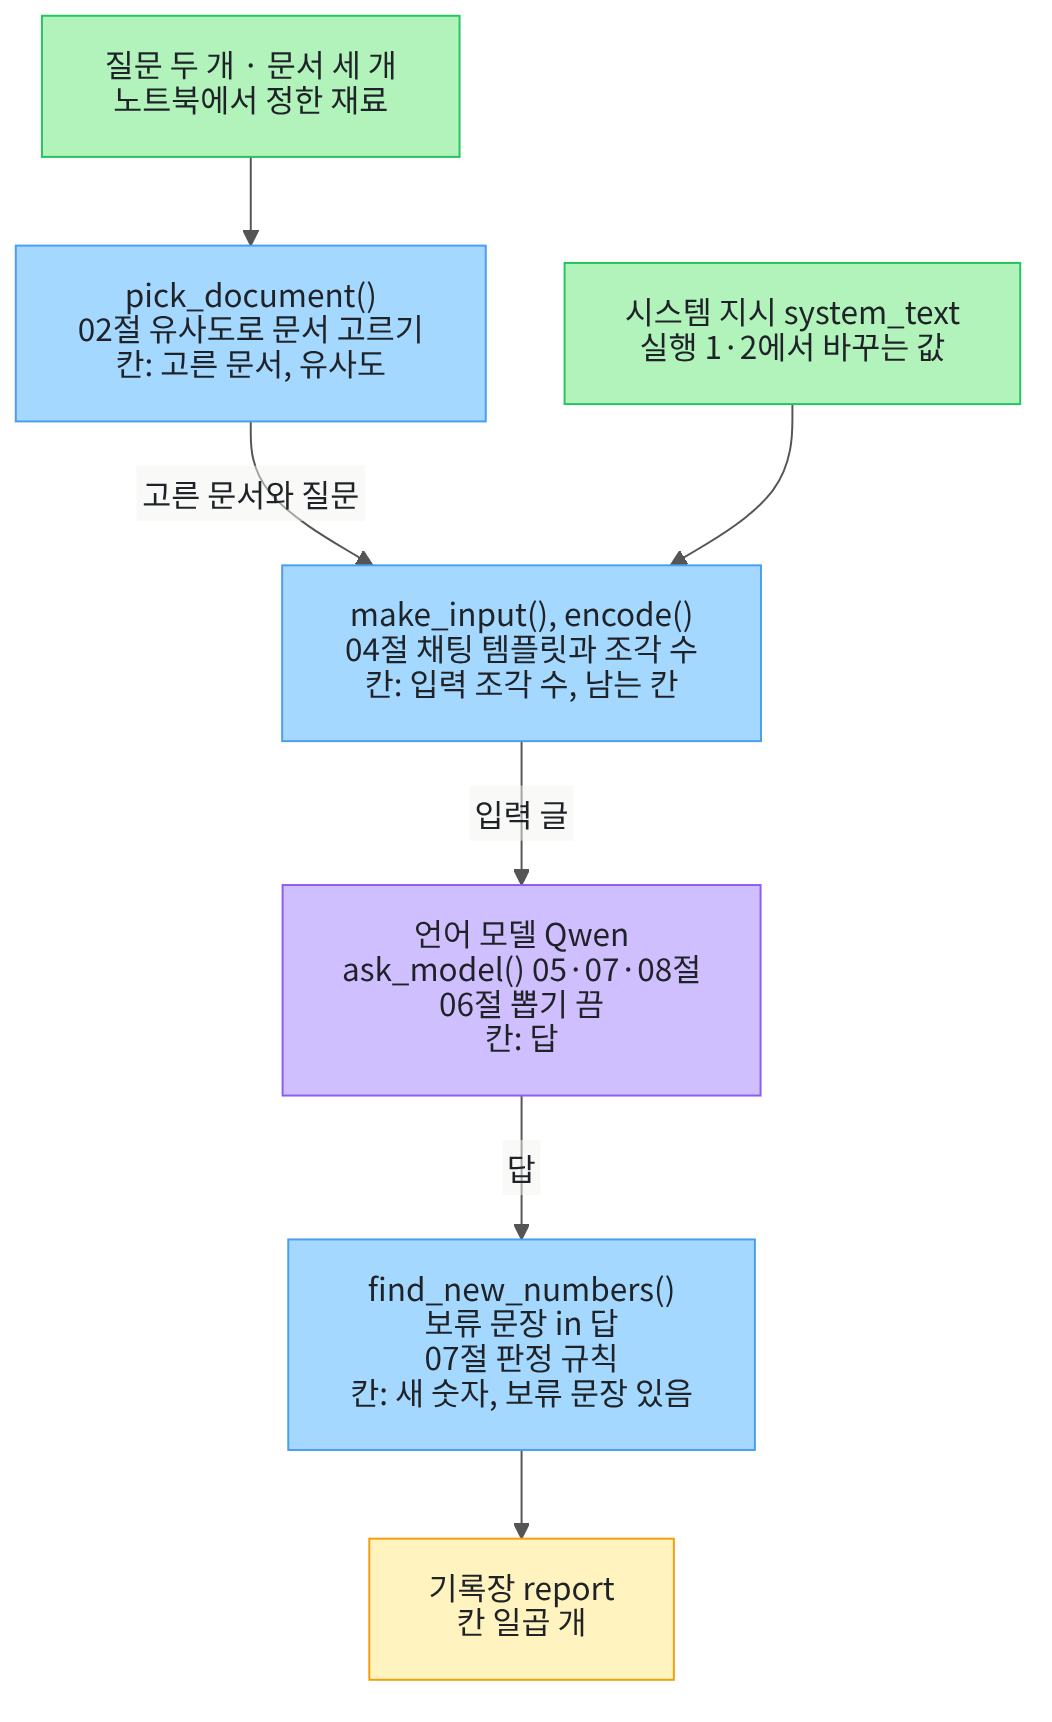

위에서 아래로 읽습니다. 초록 상자는 노트북에서 정한 질문·문서와, 실행 1·2에서 바꾸는 시스템 지시입니다.
파란 상자는 앞 절에서 배운 함수와 이 노트북에서 정의한 함수이고, 보라 상자는 답을 만드는 언어 모델입니다. 맨 아래 노란 상자가 칸 일곱 개의 기록장입니다.

## 1. 준비

이 절은 파일을 읽거나 만들지 않습니다. 준비 셀에서는 02절의 sentence-transformers와 03~08절의 transformers를 함께 불러옵니다. 패키지 NumPy는 02·03절처럼 벡터 계산에 씁니다.

함수 `warnings.filterwarnings()` 줄은 01·02절처럼 진행 표시 위젯이 없다는 경고 한 줄을 끕니다.
함수 `transformers.logging.set_verbosity_error()`는 04절처럼, 생성 셀에서 나오는 오류가 아닌 안내를 화면에 내지 않게 합니다.

앞에서 배운 함수는 `llm_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
이 노트북은 05절 `ask_model()`, 07절 `make_input()`·`find_new_numbers()`, Ch 4 06절 `print_report()`를 가져옵니다.
함수 `make_input()`과 `ask_model()`은 08절처럼 토큰화기와 모델을 인자로 받습니다.

In [1]:
# 패키지와 앞 절 함수를 불러오고, 오류가 아닌 안내 경고를 줄인 뒤 버전을 확인합니다
import warnings

# 진행 표시 위젯이 없다는 경고(TqdmWarning)는 계산과 관계없어 화면에 내지 않습니다
warnings.filterwarnings("ignore", message="IProgress not found")

import numpy as np
import sentence_transformers
import transformers
from sentence_transformers import SentenceTransformer
from transformers import AutoModelForCausalLM, AutoTokenizer
# 05절 답 받기, 07절 입력·새 숫자, Ch 4 06절 기록장 출력 함수를 도구 파일에서 가져옵니다
from llm_tools import ask_model, find_new_numbers, make_input, print_report

# 생성 셀의 안내(오류 아님)를 화면에 내지 않습니다
transformers.logging.set_verbosity_error()
print("sentence-transformers 버전:", sentence_transformers.__version__)
print("transformers 버전:", transformers.__version__)

sentence-transformers 버전: 5.1.1
transformers 버전: 4.56.2


**결과 읽기** — 출력 줄은 `sentence-transformers 버전: 5.1.1`과 `transformers 버전: 4.56.2`입니다. 준비물에 적은 기준 버전과 같습니다.

## 2. 실습 주제 — 문서를 골라 넣고 답 점검하기

작은 상담 창구를 떠올립니다. 창구에는 앞 절에서 쓴 문서 세 개가 있습니다.
04절 환불 문장, 07절 노을 워커 3 배터리 문장, 07절 해바라기 연구소 초록 패스 문장입니다.

질문이 오면 02절 유사도로 질문과 가장 가까운 문서 하나를 고릅니다. 고른 문서와 질문을 04절 채팅 템플릿으로 합쳐 모델에 넣습니다.
받은 답은 07절 판정 규칙으로 점검합니다. 확인한 값은 Ch 4 06절처럼 기록장 딕셔너리에 적습니다.

질문은 두 개입니다. 첫 질문 「환불은 며칠 이내에 신청하나요?」는 문서에 답이 있습니다.
둘째 질문 「노을 워커 3의 무게는 몇 g인가요?」는 세 문서 어디에도 답이 없습니다.

실행 1은 04절 시스템 지시 「주어진 문서 범위에서만 답하세요.」로 묻습니다. 실행 2는 시스템 지시 하나만 07절 보류 지시로 바꿔 같은 질문을 묻습니다.

언어 모델은 08절에서 선택 기준으로 고른 Qwen입니다. 03절 어텐션 비중과 06절 뽑기를 켠 생성은 이번 실습에서 쓰지 않습니다.

## 3. 재료 만들기 — 두 모델 불러오기

언어 모델은 03~08절과 같은 Qwen2.5-0.5B-Instruct입니다. 임베딩 모델은 02절과 같은 multilingual MiniLM입니다.
두 모델 모두 01절처럼 판 번호(revision)를 고정해 받습니다.

언어 모델은 03~08절처럼 이름 `model`에 담습니다. 그래서 02절에서 `model`에 담았던 임베딩 모델은 이번에는 `embedding_model`에 담아 두 모델을 구분합니다.
08절처럼 모델 두 개를 한 커널에 올리므로, 메모리가 작은 컴퓨터에서는 다른 노트북의 커널을 먼저 종료합니다.

실행 전에 예상합니다. 컨텍스트 한도는 04절의 32768, 임베딩 벡터 길이는 02절의 384일 것입니다.

In [2]:
# 03~08절 언어 모델과 토큰화기를 먼저 받고, 02절 임베딩 모델을 받습니다
model_name = "Qwen/Qwen2.5-0.5B-Instruct"
model_revision = "7ae557604adf67be50417f59c2c2f167def9a775"
tokenizer = AutoTokenizer.from_pretrained(model_name, revision=model_revision)
model = AutoModelForCausalLM.from_pretrained(model_name, revision=model_revision)
# 언어 모델 이름 model과 겹치지 않게, 임베딩 모델은 embedding_model에 담습니다
embedding_name = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
embedding_revision = "e8f8c211226b894fcb81acc59f3b34ba3efd5f42"
embedding_model = SentenceTransformer(embedding_name, revision=embedding_revision)
print("컨텍스트 한도:", model.config.max_position_embeddings)
print("임베딩 벡터 길이:", embedding_model.get_sentence_embedding_dimension())

컨텍스트 한도: 32768
임베딩 벡터 길이: 384


**결과 읽기** — 출력 줄은 `컨텍스트 한도: 32768`과 `임베딩 벡터 길이: 384`입니다. 예상과 같습니다.

이 노트북의 출력은 2026-09-21에 이 두 모델과 판 번호로 실행한 결과입니다. 실행 환경이나 버전이 바뀌면 답 문장이 달라질 수 있습니다.

## 4. 재료 만들기 — 문서 세 개

창구의 문서 세 개를 목록에 담습니다. 04·08절 환불 문장, 07·08절 배터리 문장과 초록 패스 문장입니다.

문서마다 01절처럼 Qwen 토큰화기로 조각 수를 셉니다. 이어서 02절처럼 `normalize_embeddings=True`를 주어 길이 1로 맞춘 벡터로 바꿉니다.
02절에서 본 것처럼, 길이가 1인 벡터끼리는 점곱이 곧 코사인 유사도입니다.

실행 전에 예상합니다. 배터리 문장은 08절과 같은 23조각이고, 벡터 모양은 문서 3개에 숫자 384개씩일 것입니다.
여러 줄로 나오는 표라서 라벨 줄을 먼저 출력합니다.

In [3]:
# 문서 세 개를 목록에 담고, 조각 수를 센 뒤 길이 1로 맞춘 벡터로 바꿉니다
documents = [
    "환불은 결제일로부터 7일 이내에 신청합니다.",
    "노을 워커 3의 배터리 용량은 4200mAh입니다.",
    "해바라기 연구소의 초록 패스 제도는 2026년에 연구자 한 명당 300만 원을 지원합니다.",
]
print("문서 번호 | 조각 수 | 문서")
for number in range(len(documents)):
    token_ids = tokenizer.encode(documents[number])
    print(number, "|", len(token_ids), "|", documents[number])
# normalize_embeddings=True를 주면 벡터마다 길이가 1이 되도록 나눈 값을 반환합니다
document_vectors = embedding_model.encode(documents, normalize_embeddings=True)
print("문서 벡터 모양:", document_vectors.shape)

문서 번호 | 조각 수 | 문서
0 | 17 | 환불은 결제일로부터 7일 이내에 신청합니다.
1 | 23 | 노을 워커 3의 배터리 용량은 4200mAh입니다.
2 | 37 | 해바라기 연구소의 초록 패스 제도는 2026년에 연구자 한 명당 300만 원을 지원합니다.
문서 벡터 모양: (3, 384)


**결과 읽기** — 라벨 줄 아래 세 줄은 `0 | 17 |`, `1 | 23 |`, `2 | 37 |`로 시작합니다. 마지막 줄은 `문서 벡터 모양: (3, 384)`입니다.

배터리 문장 23조각은 08절 5절의 한국어 문장 조각 수와 같습니다. 문서가 길수록 조각이 많아, 04절 연습용 한도에서 입력이 차지하는 칸도 늘어납니다.

## 5. 재료 만들기 — 질문 두 개와 정해 둘 값

질문 두 개와, 실행 1·2에서 바꾸지 않을 값을 정합니다. 연습용 한도 512와 출력 몫 64는 04절 값입니다.
입력 한도는 04절 식 `입력 한도 = 전체 한도 - 출력 몫`으로 구합니다.

보류 문장은 07절에서 정한 글 「제공된 정보로는 확인할 수 없습니다」입니다. 07절 판정 규칙은 답에 이 글이 들어 있으면 보류한 답으로 봅니다.

실행 전에 예상합니다. 입력 한도는 04절처럼 448일 것입니다.

In [4]:
# 질문 두 개, 04절 연습용 한도와 출력 몫, 07절 보류 문장을 정합니다
questions = ["환불은 며칠 이내에 신청하나요?", "노을 워커 3의 무게는 몇 g인가요?"]
practice_window = 512
output_budget = 64
input_budget = practice_window - output_budget
abstain_sentence = "제공된 정보로는 확인할 수 없습니다"
print("질문 수:", len(questions))
print("입력 한도:", input_budget)

질문 수: 2
입력 한도: 448


**결과 읽기** — 출력 줄은 `질문 수: 2`와 `입력 한도: 448`입니다. 예상과 같습니다.

첫 질문은 04·08절과 같은 질문이고, 둘째 질문은 이 실습에서 새로 만든 질문입니다. 둘째 질문의 제품 이름은 07절에서 교재가 지어낸 이름입니다.

## 6. 부품 준비 — 가장 가까운 문서 고르기

첫 부품은 질문과 가장 가까운 문서를 고르는 함수 `pick_document()`입니다. 질문을 길이 1로 맞춘 벡터로 바꾸고, 문서 벡터 세 개와 점곱을 계산합니다.
점곱은 03절처럼 표 `@` 벡터로 한 번에 구합니다. 문서 벡터 표(3행 384열)의 행마다 질문 벡터와 점곱을 구해, 유사도 세 개가 나옵니다.

문서마다 유사도를 출력하고, 03절 함수 `np.argmax()`로 유사도가 가장 큰 자리를 찾습니다. 반환값은 그 문서와 유사도 두 개라서 08절처럼 튜플로 받습니다.
함수 안에서 바깥 이름 `embedding_model`, `documents`, `document_vectors`를 읽습니다. 이 셀은 함수를 정의만 합니다.

In [5]:
# 질문과 문서 세 개의 유사도를 출력하고, 가장 큰 문서와 그 유사도를 반환하는 함수를 정의합니다
def pick_document(question):
    # 02절처럼 목록으로 넣고, 길이 1로 맞춘 질문 벡터를 받습니다
    question_vectors = embedding_model.encode([question], normalize_embeddings=True)
    # 표 @ 벡터로 문서마다 점곱을 구합니다. 길이 1인 벡터끼리는 점곱이 곧 코사인 유사도입니다
    similarities = document_vectors @ question_vectors[0]
    for number in range(len(documents)):
        print("문서", number, "유사도:", round(similarities[number], 4))
    # np.argmax()는 가장 큰 값이 있는 자리 번호를 반환합니다
    best_number = np.argmax(similarities)
    return documents[best_number], round(similarities[best_number], 4)

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다.

## 7. 부품 준비 — 가져온 함수 네 개

나머지 부품과 기록 장치는 앞 절에서 배운 함수라, 준비 셀에서 `llm_tools.py`로 가져왔습니다. 새로 정의하지 않고 하는 일만 확인합니다.

- 07절 `make_input(tokenizer, system_text, user_text)`: 시스템 지시가 빈 글이 아니면 시스템 메시지로 앞에 넣고, 채팅 템플릿으로 합친 입력 글을 반환합니다.
- 05절 `ask_model(model, tokenizer, input_text, output_budget)`: 06절에서 본 뽑기를 끈 설정(`do_sample=False`)으로 답을 만듭니다.
- 07절 `find_new_numbers(answer, source_text)`: 답의 숫자 가운데 기준 글에 없던 숫자, 곧 새 숫자만 모아 반환합니다.
- Ch 4 06절 `print_report(report)`: 기록장 딕셔너리를 칸마다 한 줄씩 출력합니다.

이번 실습은 두 실행 모두 시스템 지시를 넣습니다. 05절에서는 같은 기기에서 같은 입력을 다시 넣었을 때 같은 답이 나왔습니다.

새 숫자의 기준 글에는 모델이 받은 입력 글 전체를 넣습니다. 입력 글은 시스템 지시, 고른 문서, 질문을 채팅 템플릿으로 합친 글입니다.
그래서 새 숫자는 모델이 받은 글 어디에도 없던 숫자입니다. 두 실행을 비교하려고 Ch 2 13절과 Ch 4 06절처럼 딕셔너리를 기록장으로 씁니다.

## 8. 조립하기 — 질문에서 기록장까지

조립 함수 `run_check()`는 질문과 시스템 지시를 받아, 부품을 차례로 부르고 기록장을 반환합니다. 주석마다 그 줄이 쓰는 절을 적었습니다.

기록장 칸은 일곱 개입니다. 고른 문서, 유사도, 입력 조각 수, 남는 칸, 답, 새 숫자, 보류 문장 있음입니다.
남는 칸은 04절처럼 입력 한도에서 실제 입력 조각 수를 뺀 값입니다. 답은 05절처럼 줄바꿈을 빈칸으로 바꿔 한 줄로 적습니다.

함수 안에서 바깥 이름 `tokenizer`, `model`, `output_budget`, `input_budget`, `abstain_sentence`를 읽습니다. 이 셀은 함수를 정의만 합니다.

In [6]:
# 조립: 문서 고르기 → 입력 만들기 → 답 받기 → 판정까지 기록장에 적습니다
def run_check(question, system_text):
    # 02절 유사도로 가장 가까운 문서 고르기
    document, similarity = pick_document(question)
    # 04절 채팅 템플릿으로 시스템 지시·문서·질문을 합치고, 01절처럼 조각으로 나누기
    input_text = make_input(tokenizer, system_text, document + "\n" + question)
    input_ids = tokenizer.encode(input_text)
    # 05·06절 뽑기를 끈 설정으로 답 받기
    answer = ask_model(model, tokenizer, input_text, output_budget)
    report = {"고른 문서": document, "유사도": similarity, "입력 조각 수": len(input_ids)}
    # 04절 입력 한도에서 실제 입력을 빼고 남는 칸
    report["남는 칸"] = input_budget - len(input_ids)
    report["답"] = answer.replace("\n", " ")
    # 07절 판정 규칙: 입력에 없던 숫자와 보류 문장
    report["새 숫자"] = find_new_numbers(answer, input_text)
    report["보류 문장 있음"] = abstain_sentence in answer
    return report

**결과 읽기** — 정의만 하는 셀이라 출력이 없습니다. 조립이 끝났으니, 이제 질문과 시스템 지시만 넣어 부르면 됩니다.

## 9. 실행 1 — 04절 시스템 지시

변수 `system_text`에 04절 시스템 지시를 담고, 질문 두 개로 조립 함수를 차례로 부릅니다.
기록장은 질문마다 칸별로 출력하고, 비교하려고 목록 `reports_1`에 모읍니다. 언어 모델은 질문마다 한 번씩, 모두 2번 답을 만듭니다.

실행 전에 예상합니다. 첫 질문은 환불 문서를, 둘째 질문은 제품 이름이 같은 배터리 문서를 고를 것입니다.
첫 질문은 문서 범위에서만 답하라고 했으니 7일이라고 답할 것입니다. 둘째 질문은 문서에 무게가 없으니, 모른다고 하거나 숫자를 지어낼 것입니다.

In [7]:
# 실행 1: 04절 시스템 지시로 질문 두 개를 차례로 점검합니다
system_text = "주어진 문서 범위에서만 답하세요."
reports_1 = []
for question in questions:
    print("질문:", question)
    report = run_check(question, system_text)
    reports_1.append(report)
    print("기록장:")
    print_report(report)

질문: 환불은 며칠 이내에 신청하나요?
문서 0 유사도: 0.7636
문서 1 유사도: 0.0601
문서 2 유사도: 0.1694


기록장:
고른 문서 | 환불은 결제일로부터 7일 이내에 신청합니다.
유사도 | 0.7636
입력 조각 수 | 57
남는 칸 | 391
답 | 환불은 결제일로부터 14일 이내에 신청합니다.<|im_end|>
새 숫자 | ['14']
보류 문장 있음 | False
질문: 노을 워커 3의 무게는 몇 g인가요?
문서 0 유사도: 0.0088
문서 1 유사도: 0.5174
문서 2 유사도: 0.2714


기록장:
고른 문서 | 노을 워커 3의 배터리 용량은 4200mAh입니다.
유사도 | 0.5174
입력 조각 수 | 66
남는 칸 | 382
답 | 노을 워커 3의 무게는 약 150g 입니다.<|im_end|>
새 숫자 | ['150']
보류 문장 있음 | False


**결과 읽기** — 첫 질문은 `문서 0 유사도: 0.7636`인 환불 문서를 골랐고, `입력 조각 수 | 57`, `남는 칸 | 391`입니다. 답은 `환불은 결제일로부터 14일 이내에 신청합니다.<|im_end|>`이고 `새 숫자 | ['14']`입니다.

둘째 질문은 `문서 1 유사도: 0.5174`인 배터리 문서를 골랐고, `입력 조각 수 | 66`입니다. 답은 `노을 워커 3의 무게는 약 150g 입니다.<|im_end|>`이고 `새 숫자 | ['150']`입니다.

예상과 달리 첫 답은 문서의 7일을 14일로 바꿨습니다. 08절에서 시스템 메시지 없이 같은 문서와 질문을 넣었을 때도 답에 14일이 나왔습니다.
두 답 모두 `보류 문장 있음 | False`입니다. 07절 새 숫자 규칙이 입력에 없던 14와 150을 잡았습니다.

둘째 질문의 유사도 0.5174는 첫 질문의 0.7636보다 낮지만, 세 문서 가운데서는 가장 컸습니다. 가장 가까운 문서를 골라도, 그 문서에 답이 있다는 보장은 없습니다.
모델은 배터리 문서를 받고도 문서에 없는 무게를 적었습니다.

## 10. 실행 2 — 시스템 지시 하나만 바꾸기

바꾸는 값은 시스템 지시 `system_text` 하나입니다. 07절 9절의 보류 지시로 바꾸고, 같은 질문 두 개로 같은 조립 함수를 부릅니다.
문서, 질문, 출력 몫, 판정 규칙은 그대로입니다.

실행 전에 예상합니다. 고른 문서와 유사도는 시스템 지시를 쓰지 않으니 실행 1과 같을 것입니다. 보류 지시가 04절 지시보다 길어서, 입력 조각 수는 늘고 남는 칸은 줄 것입니다.

07절에서는 보류 지시를 넣자 문서 없는 질문은 보류했지만, 문서가 있는 질문 하나도 보류했습니다.
그래서 둘째 질문은 보류하고, 첫 질문도 보류할 수 있다고 예상합니다.

In [8]:
# 실행 2: 시스템 지시 하나만 07절 보류 지시로 바꾸고, 같은 질문 두 개를 점검합니다
system_text = "주어진 질문에 정답 근거가 없으면 추측하지 말고 '제공된 정보로는 확인할 수 없습니다'라고 답하세요."
reports_2 = []
for question in questions:
    print("질문:", question)
    report = run_check(question, system_text)
    reports_2.append(report)
    print("기록장:")
    print_report(report)

질문: 환불은 며칠 이내에 신청하나요?
문서 0 유사도: 0.7636
문서 1 유사도: 0.0601
문서 2 유사도: 0.1694


기록장:
고른 문서 | 환불은 결제일로부터 7일 이내에 신청합니다.
유사도 | 0.7636
입력 조각 수 | 79
남는 칸 | 369
답 | 7일 이내에<|im_end|>
새 숫자 | []
보류 문장 있음 | False
질문: 노을 워커 3의 무게는 몇 g인가요?
문서 0 유사도: 0.0088
문서 1 유사도: 0.5174
문서 2 유사도: 0.2714


기록장:
고른 문서 | 노을 워커 3의 배터리 용량은 4200mAh입니다.
유사도 | 0.5174
입력 조각 수 | 88
남는 칸 | 360
답 | 제공된 정보로는 확인할 수 없습니다.<|im_end|>
새 숫자 | []
보류 문장 있음 | True


**결과 읽기** — 유사도 줄은 실행 1과 같고, 입력 조각 수는 `입력 조각 수 | 79`와 `입력 조각 수 | 88`, 남는 칸은 `남는 칸 | 369`와 `남는 칸 | 360`입니다.
첫 질문의 답은 `7일 이내에<|im_end|>`이고 `새 숫자 | []`입니다. 둘째 질문의 답은 `제공된 정보로는 확인할 수 없습니다.<|im_end|>`이고 `보류 문장 있음 | True`입니다.

예상대로 입력은 질문마다 22조각 늘었습니다. 문서와 질문이 같으니, 늘어난 조각은 두 시스템 지시의 길이 차이입니다.

예상과 달리 첫 질문은 보류하지 않고, 문서의 7일을 적었습니다. 07절에서 문서가 있는데도 보류한 질문과는 결과가 달랐습니다.
질문 두 개로 한 번 본 결과라서, 보류 지시가 늘 답을 고친다고 말할 수는 없습니다.

## 11. 두 기록장 비교하기

두 실행의 기록장을 질문마다 같은 키끼리 비교합니다. Ch 4 06절 비교 셀과 같은 모양이고, 기호 `!=`는 「두 값이 다른가」 비교입니다.
바깥 `for`는 질문 번호를 하나씩 바꾸고, 안쪽 `for`는 기록장의 칸을 차례로 읽습니다.

검사 줄 `assert`는 두 실행의 고른 문서가 같은지 확인합니다. 문서 고르기는 시스템 지시를 쓰지 않으므로 매번 같아야 하는 값입니다.

실행 전에 예상합니다. 고른 문서와 유사도는 같고, 입력 조각 수·남는 칸·답·새 숫자는 달라질 것입니다. 보류 문장 칸은 둘째 질문에서만 달라질 것입니다.

In [9]:
# 두 실행의 기록장을 질문마다 칸별로 비교하고, 달라진 칸의 수를 셉니다
changed_count = 0
for number in range(len(questions)):
    print("질문 번호:", number)
    for key, value_1 in reports_1[number].items():
        value_2 = reports_2[number][key]
        if value_1 != value_2:
            print("달라짐 |", key, "|", value_1, "->", value_2)
            changed_count = changed_count + 1
        else:
            print("같음 |", key, "|", value_1)
    # 문서 고르기는 시스템 지시를 쓰지 않으므로 두 실행이 같아야 합니다
    assert reports_1[number]["고른 문서"] == reports_2[number]["고른 문서"]
print("달라진 칸 수:", changed_count)

질문 번호: 0
같음 | 고른 문서 | 환불은 결제일로부터 7일 이내에 신청합니다.
같음 | 유사도 | 0.7636
달라짐 | 입력 조각 수 | 57 -> 79
달라짐 | 남는 칸 | 391 -> 369
달라짐 | 답 | 환불은 결제일로부터 14일 이내에 신청합니다.<|im_end|> -> 7일 이내에<|im_end|>
달라짐 | 새 숫자 | ['14'] -> []
같음 | 보류 문장 있음 | False
질문 번호: 1
같음 | 고른 문서 | 노을 워커 3의 배터리 용량은 4200mAh입니다.
같음 | 유사도 | 0.5174
달라짐 | 입력 조각 수 | 66 -> 88
달라짐 | 남는 칸 | 382 -> 360
달라짐 | 답 | 노을 워커 3의 무게는 약 150g 입니다.<|im_end|> -> 제공된 정보로는 확인할 수 없습니다.<|im_end|>
달라짐 | 새 숫자 | ['150'] -> []
달라짐 | 보류 문장 있음 | False -> True
달라진 칸 수: 9


**결과 읽기** — 마지막 줄은 `달라진 칸 수: 9`입니다. 첫 질문은 네 칸, 둘째 질문은 다섯 칸이 달라졌고, 검사 줄 `assert`도 멈추지 않았습니다.
두 질문 모두 고른 문서와 유사도(`같음 | 유사도 | 0.7636`, `같음 | 유사도 | 0.5174`)가 같았습니다. 첫 질문은 `같음 | 보류 문장 있음 | False`도 같았습니다.

바꾼 값은 시스템 지시 하나이고, 문서 고르기는 그대로였습니다. 지시가 들어간 입력부터 조각 수와 답이 달라졌습니다.
실행 1에서 잡힌 새 숫자 두 개는 실행 2에서 나오지 않았습니다. 이 결과는 질문 두 개와 모델 하나로 한 번 본 것입니다.

## 정리

- 02절 유사도, 04절 입력 한도, 05·06절 뽑기를 끈 답, 07절 판정 규칙을 조립 함수 하나로 이었습니다.
- 실행 1(04절 지시)에서 환불 답은 문서의 7일을 14일로 바꿨습니다. 무게 답은 150g을 지어냈고, 새 숫자 규칙이 두 숫자를 잡았습니다.
- 실행 2(07절 보류 지시)에서 입력은 22조각 늘었고, 환불 답은 7일, 무게 질문은 보류 문장이었습니다. 질문 두 개로 한 번 본 결과입니다.

이 절로 Ch 5가 끝납니다. Ch 6에서는 인터넷 서비스의 모델을 LangChain의 공통 방식으로 부릅니다.
Ch 9에서는 이 실습의 문서 고르기를, 질문과 가까운 문서 덩어리(청크)를 가져오는 검색 단계로 다시 배웁니다.